# 2.2 Respuesta transitoria y estado estacionario

La respuesta al escalón permite observar cómo cambia la salida desde su
condición inicial y, si el sistema se estabiliza, cuál es su valor final. En
esta sección usamos entrada escalón unitario, condiciones iniciales nulas y
modelos continuos SISO.

## Sistema de primer orden

Para una ganancia estática $K$ y una constante de tiempo $\tau>0$:

$$G(s)=\frac{K}{\tau s+1},\qquad y(t)=K\left(1-e^{-t/\tau}\right),\quad t\geq0.$$

Su polo es $-1/\tau$ y $y(\tau)\approx0.632K$. Una constante de tiempo menor
produce una respuesta más rápida. Si $K\ne0$, la entrada a la banda del 2 % del
valor final ocurre en $t=-\tau\ln(0.02)\approx3.91\tau$; como la respuesta es
monótona, no vuelve a salir de ella.

En el ejemplo $K=1$ y $\tau=1$ s. Tomamos $G$ como la relación de lazo
cerrado entre referencia y salida, de modo que $e(t)=1-y(t)$. Sin esa
interpretación, este error no debe confundirse con el de un lazo específico.

**Objetivo:** relacionar parámetros, polos, respuesta transitoria y valor final.

Error al final del intervalo: 0.0003354626279027384
Tiempo aproximado para error menor al 2%: 3.92 s


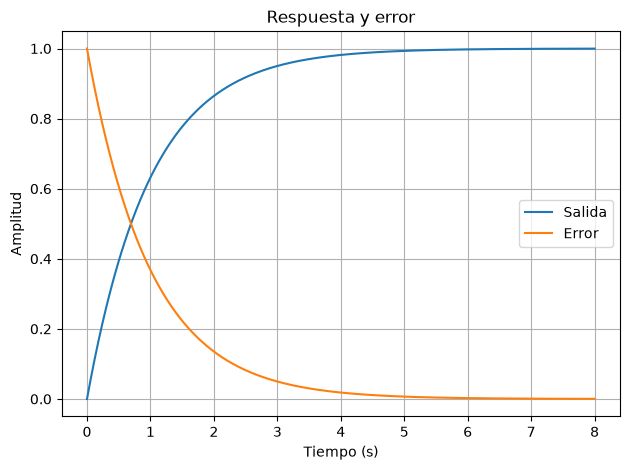

In [1]:
%matplotlib inline
import numpy as np
from scipy import signal
from sistemas_dinamicos import graficar

t = np.linspace(0, 8, 801)
_, y = signal.step(signal.TransferFunction([1], [1, 1]), T=t)
error = 1 - y
graficar(t, {"Salida": y, "Error": error}, titulo="Respuesta y error");
print("Error al final del intervalo:", error[-1])
print("Tiempo aproximado para error menor al 2%:", t[np.flatnonzero(error < 0.02)[0]], "s")


El error tiende a cero. En esta respuesta monótona, la primera entrada en la banda del 2 % coincide con el establecimiento; en una respuesta oscilatoria habría que comprobar que no vuelva a salir.

**Practica:** cambia la constante de tiempo y explica cómo cambia la duración del transitorio.

### Primer orden en espacio de estados

Una realización posible toma el estado como la salida, $x=y$:

$$\dot x=-\frac{1}{\tau}x+\frac{K}{\tau}u,\qquad y=x.$$

Por tanto, $A=[-1/\tau]$, $B=[K/\tau]$, $C=[1]$ y $D=[0]$. Para
el ejemplo $K=\tau=1$ son $A=[-1]$, $B=C=[1]$ y $D=[0]$. En general,
una misma función de transferencia puede tener distintas realizaciones.

Comprobamos que la respuesta del modelo de estados coincide con la calculada
arriba mediante la función de transferencia; ambas parten de estado cero.

In [ ]:
A_primero = np.array([[-1.0]])
B_primero = np.array([[1.0]])
C_primero = np.array([[1.0]])
D_primero = np.array([[0.0]])
modelo_primero_estados = signal.StateSpace(A_primero, B_primero, C_primero, D_primero)
_, y_primero_estados = signal.step(modelo_primero_estados, T=t)
print("A =", A_primero, "B =", B_primero, "C =", C_primero, "D =", D_primero)
print("Diferencia máxima de respuestas:", np.max(np.abs(y - y_primero_estados)))

## Sistema de segundo orden

Consideramos el modelo estándar **sin ceros**, con ganancia estática unitaria:

$$G(s)=\frac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2},\qquad
\ddot y+2\zeta\omega_n\dot y+\omega_n^2y=\omega_n^2u(t).$$

Aquí $\omega_n>0$ es la frecuencia natural no amortiguada (rad/s) y $\zeta$
es la razón de amortiguamiento, adimensional. Los polos son
$s=-\zeta\omega_n\pm\omega_n\sqrt{\zeta^2-1}$.

| Caso | Polos y respuesta al escalón |
|---|---|
| **No amortiguado:** $\zeta=0$ | Polos imaginarios puros; oscila indefinidamente y no alcanza un valor final. |
| **Subamortiguado:** $0<\zeta<1$ | Polos complejos con parte real negativa; oscila con amplitud decreciente y presenta sobreimpulso. |
| **Críticamente amortiguado:** $\zeta=1$ | Un polo real doble negativo; alcanza el valor final sin oscilación ni sobreimpulso. |
| **Sobreamortiguado:** $\zeta>1$ | Dos polos reales negativos distintos; no oscila y, para este modelo, su respuesta es monótona. |

Si $\zeta<0$, los polos tienen parte real positiva y el sistema es inestable.
Para $\zeta>0$, el valor final ante el escalón unitario es $1$. El caso crítico
es el más rápido sin sobreimpulso **dentro de esta familia estándar con
$\omega_n$ fijo**; la presencia de ceros puede cambiar estas conclusiones.

### Comparación de respuestas

Fijamos $\omega_n=2$ rad/s y cambiamos únicamente $\zeta$. Las curvas tienen
el mismo valor final teórico salvo la no amortiguada, que oscila sin converger.
La línea de referencia ayuda a identificar el sobreimpulso.

In [ ]:
omega_n = 2.0  # rad/s
t_segundo = np.linspace(0, 20, 2001)
casos = {
    "No amortiguado (ζ=0)": 0.0,
    "Subamortiguado (ζ=0.3)": 0.3,
    "Subamortiguado (ζ=0.7)": 0.7,
    "Crítico (ζ=1)": 1.0,
    "Sobreamortiguado (ζ=1.5)": 1.5,
}
respuestas = {}
for nombre, zeta in casos.items():
    sistema = signal.TransferFunction([omega_n**2],
                                      [1, 2*zeta*omega_n, omega_n**2])
    _, respuestas[nombre] = signal.step(sistema, T=t_segundo)

fig, ax = graficar(t_segundo, respuestas, titulo="Respuesta al escalón: segundo orden",
                   ylabel="Salida y(t)")
ax.axhline(1, color="black", linewidth=0.8, alpha=0.6, label="Referencia")
ax.legend();

### Segundo orden en espacio de estados

Tomando $x_1=y$ y $x_2=\dot y$, se obtiene una realización válida **para
todos los valores de $\zeta$ de la tabla**, incluido el caso no amortiguado:

$$\begin{bmatrix}\dot x_1\\\dot x_2\end{bmatrix}=
\underbrace{\begin{bmatrix}0&1\\-\omega_n^2&-2\zeta\omega_n\end{bmatrix}}_{A}
\begin{bmatrix}x_1\\x_2\end{bmatrix}+
\underbrace{\begin{bmatrix}0\\\omega_n^2\end{bmatrix}}_{B}u,\quad
y=\underbrace{\begin{bmatrix}1&0\end{bmatrix}}_{C}
\begin{bmatrix}x_1\\x_2\end{bmatrix}+\underbrace{0}_{D}u.$$

Con $\omega_n=2$ rad/s se tiene $B=[0,4]^T$, $C=[1,0]$, $D=0$, mientras que
$A$ cambia con $\zeta$. Calculamos las matrices y los autovalores de cada caso
y verificamos su respuesta frente a la función de transferencia correspondiente.

In [ ]:
B_segundo = np.array([[0.0], [omega_n**2]])
C_segundo = np.array([[1.0, 0.0]])
D_segundo = np.array([[0.0]])
modelos_estados = {}
for nombre, zeta_caso in casos.items():
    A = np.array([[0.0, 1.0], [-omega_n**2, -2*zeta_caso*omega_n]])
    modelo = signal.StateSpace(A, B_segundo, C_segundo, D_segundo)
    modelos_estados[nombre] = modelo
    _, salida_estado = signal.step(modelo, T=t_segundo)
    print(f"\n{nombre}: A =\n{A}")
    print("Autovalores:", np.linalg.eigvals(A))
    print("Diferencia máxima de respuestas:",
          np.max(np.abs(salida_estado - respuestas[nombre])))
print("\nPara todos: B =", B_segundo.ravel(), "C =", C_segundo, "D =", D_segundo)

### Sobreimpulso en el caso subamortiguado

El sobreimpulso porcentual respecto al valor final es
$M_p=100(y_{\max}-y_\infty)/|y_\infty|$. En el modelo estándar, con
$0<\zeta<1$, su valor teórico es
$M_p=100e^{-\pi\zeta/\sqrt{1-\zeta^2}}$ y el primer pico ocurre en
$t_p=\pi/(\omega_n\sqrt{1-\zeta^2})$. Comparemos la fórmula con la curva
muestreada para $\zeta=0.3$:

In [ ]:
zeta = 0.3
y_sub = respuestas["Subamortiguado (ζ=0.3)"]
indice_pico = np.argmax(y_sub)
mp_numerico = 100 * (y_sub[indice_pico] - 1)
mp_teorico = 100 * np.exp(-np.pi*zeta / np.sqrt(1-zeta**2))
tp_teorico = np.pi / (omega_n*np.sqrt(1-zeta**2))
print(f"Sobreimpulso numérico: {mp_numerico:.2f} %")
print(f"Sobreimpulso teórico: {mp_teorico:.2f} %")
print(f"Tiempo del pico numérico: {t_segundo[indice_pico]:.3f} s")
print(f"Tiempo del pico teórico: {tp_teorico:.3f} s")

La pequeña diferencia se debe al muestreo temporal. En sistemas oscilatorios,
el **tiempo de establecimiento** es el instante a partir del cual la respuesta
permanece dentro de la banda elegida; no basta con su primera entrada en ella.
La aproximación $t_s\approx4/(\zeta\omega_n)$ para la banda del 2 % es una
regla práctica para el caso subamortiguado, no una igualdad exacta ni una
fórmula general para todos los casos.

**Practica:** compara $\zeta=0.3$ y $\zeta=0.7$ en la gráfica; calcula sus
sobreimpulsos teóricos. Después cambia $\omega_n$ y observa cómo se modifica
la escala de tiempo manteniendo $\zeta$ constante.

## Estado estacionario y teorema del valor final

El **estado estacionario** describe lo que permanece después de desaparecer
el transitorio. Para una entrada constante y una respuesta que converge, es un
valor constante; en otros casos puede ser una oscilación permanente o incluso
no existir una respuesta estacionaria acotada.

Si $Y(s)=\mathcal L\{y(t)\}$ y **todos los polos de $sY(s)$ están
estrictamente en el semiplano izquierdo**, el teorema del valor final permite
calcular:

$$y(\infty)=\lim_{t\to\infty}y(t)=\lim_{s\to0}sY(s).$$

Primero calculamos $Y(s)$, después verificamos los polos de $sY(s)$ y solo
entonces calculamos el límite. Para una entrada escalón de amplitud $U_0$,
$U(s)=U_0/s$. Con condiciones iniciales nulas, $Y(s)=G(s)U(s)$.
Así, si se cumplen las condiciones, $y(\infty)=U_0G(0)$.

**Primer orden:** $sY(s)=KU_0/(\tau s+1)$, cuyo polo es $-1/\tau$.
Para $\tau>0$, $y(\infty)=KU_0$. Con $K=U_0=1$, el valor final es 1.

**Segundo orden estándar:** $sY(s)=U_0\omega_n^2/
(s^2+2\zeta\omega_n s+\omega_n^2)$. Para $\omega_n>0$ y $\zeta>0$,
ambos polos tienen parte real negativa y $y(\infty)=U_0=1$ en el ejemplo.

**Advertencia:** con $\zeta=0$ los polos están sobre el eje imaginario y el
teorema no se aplica. Aunque la sustitución formal $s\to0$ dé 1, la respuesta
es $y(t)=1-\cos(\omega_n t)$ y oscila indefinidamente: **no tiene límite**.
Para $\zeta<0$, hay polos con parte real positiva y tampoco se aplica.

In [ ]:
import sympy as sp

s = sp.symbols("s")
Y_primero = 1 / (s*(s+1))
Y_segundo_sub = 4 / (s*(s**2 + sp.Rational(6, 5)*s + 4))
Y_segundo_no_amortiguado = 4 / (s*(s**2 + 4))
for nombre, Y in [
    ("Primer orden", Y_primero),
    ("Segundo orden, ζ=0.3", Y_segundo_sub),
    ("Segundo orden, ζ=0 (no aplicar el teorema)", Y_segundo_no_amortiguado),
]:
    sY = sp.cancel(s*Y)
    polos = sp.nroots(sp.denom(sY))
    print(f"{nombre}: sY(s) = {sY}, polos = {polos}")
    if nombre.startswith("Segundo orden, ζ=0 ("):
        print("El límite algebraico es", sp.limit(sY, s, 0),
              "pero los polos imaginarios impiden aplicar el teorema.")
    else:
        print("Valor final:", sp.limit(sY, s, 0))

### Valor estacionario desde espacio de estados

Para $\dot x=Ax+Bu$, $y=Cx+Du$ y una entrada constante $u=U_0$, un equilibrio
satisface $0=Ax_{\rm eq}+BU_0$. Si $A$ es invertible:

$$x_{\rm eq}=-A^{-1}BU_0,\qquad
y_{\rm eq}=Cx_{\rm eq}+DU_0.$$

Es un **equilibrio algebraico**; solo corresponde al valor al que converge la
respuesta si los modos implicados son estables. En las realizaciones de este
ejemplo, $A$ es Hurwitz para $\zeta>0$, por lo que todas sus condiciones
iniciales convergen al equilibrio. En el caso no amortiguado, el equilibrio
existe pero una trayectoria que empieza en cero oscila a su alrededor.

Para el primer orden con $K=\tau=U_0=1$, $x_{\rm eq}=y_{\rm eq}=1$.
En todos los casos estándar de segundo orden, $x_{\rm eq}=[1,0]^T$ e
$y_{\rm eq}=1$; esto **no implica convergencia** para $\zeta=0$.

In [ ]:
def equilibrio_constante(modelo, entrada=1.0):
    x_eq = np.linalg.solve(modelo.A, -modelo.B[:, 0]*entrada)
    y_eq = (modelo.C @ x_eq + modelo.D[:, 0]*entrada)[0]
    return x_eq, y_eq

print("Primer orden: x_eq, y_eq =", equilibrio_constante(modelo_primero_estados))
for nombre, modelo in modelos_estados.items():
    x_eq, y_eq = equilibrio_constante(modelo)
    print(f"{nombre}: x_eq={x_eq}, y_eq={y_eq:.3f}")
print("Para ζ=0 existe equilibrio, pero la respuesta desde x(0)=0 no converge.")

**Practica:** calcula el valor final para un escalón de amplitud $U_0=2$
usando Laplace y el equilibrio de estados. Repite con $\zeta=0$ y explica por
qué el equilibrio algebraico no garantiza que la salida alcance un valor final.